<a href="https://colab.research.google.com/github/dsb4k8/Machine-Learning/blob/main/Subset_Selection_(Resampling)_in_R.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Cross Validation and the Bootstrap
_Cross-validation and the bootstrap are two of the most powerful resampling techniques used to assess a model's performance and quantify the uncertainty of its estimates without requiring a completely new dataset._


In [80]:
##Grabbing the ISLR library: https://cran.r-project.org/web/packages/ISLR2/index.html
install.packages("ISLR")
install.packages("boot")

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



##Validation set approach
Validation sets can be used to estimate test error rated resulting from fitting various linear models (lm) on - in this case - automotive data


For random sampling, RNG is required - but RNG alone introduces problems for reproducability.

For this reason, we first set a fixed `seed value` such that your machine produces the same random values as mine.



#### TASK 1)  Change the value of the seed for (Validation Set Approach) part 1 to the last 4 numbers of your student ID .

Report the test rates for a Poly fit quadratic and cubic using the seed. -- IMPORTANT: your assignment will only be graded if you use the last 4 numbers of your student ID as the seed.  

In [81]:
library(ISLR)
library(glue)
set.seed(7829)

##Splitting the data into different Test / Training Ratios
The `sample()` method is used for splitting the data into 2 subsets.
- First,
generating a dataset of numbers from [1 - 392],
- then,
taking 192 if them at random and assigning them to the variable train.
This variable stores our training set

_for docs, run `?sample` in a separate cell._

In [82]:
train_50 <-sample(392, 196)

For the sake of comparison, lets test a few other splits:
we already have a 50/50 training. lets also do:

- 60%, 70%, and 70%

test percentage splits

In [83]:
392 * 0.5
392 * 0.6
392 * .7
392 * .8

[1] 196

[1] 235.2

[1] 274.4

[1] 313.6

####Splitting the data + Quality of Life Update

Since we are working with 4 configuations, lets make a function which wraps the core logic - allowing us just to pass the appropiate parameters


#### TASK 2) Change the ratio of train/test to a new percentage. (original was 50/50)

- Select 3 new ratios and compute and report the test performance for each using the best performing of the two Poly fit values from task 1. Keep your student ID as the seed.

In [84]:
test_train_split <- function(total_pop, trainPercentage) {
  #Resetting the seed for each split to ensure we are comparing apples to apples
  #otherwise the seed with drift with each sample call (within test_train_split)
  set.seed(7829)
  return (sample(total_pop, total_pop*trainPercentage))
}
train_60 <- test_train_split(392, 0.60) # 235
train_70 <- test_train_split(392, 0.70) # 274
train_80 <- test_train_split(392, 0.80) # 313

##Running Linear Regression on the training sets
We now have 4 lists of 4 sample sizes:


`train_60` for example contains a list of 235 randomly sampled numbers taken from the original set  (1 - 392).

We use this list of random integers as indicies against the cohort of 392.

Then we fit the data using linear regression - comparing mpg against horsepower using the subset of data we sampled.

In [85]:
lm.fit50 <- lm(mpg ~ horsepower, data = Auto, subset = train_50)
lm.fit60 <- lm(mpg ~ horsepower, data = Auto, subset = train_60)
lm.fit70 <- lm(mpg ~ horsepower, data = Auto, subset = train_70)
lm.fit80 <- lm(mpg ~ horsepower, data = Auto, subset = train_80)

In [86]:
attach(Auto)

The following objects are masked from Auto (pos = 3):

    acceleration, cylinders, displacement, horsepower, mpg, name,
    origin, weight, year


The following objects are masked from Auto (pos = 5):

    acceleration, cylinders, displacement, horsepower, mpg, name,
    origin, weight, year




###Calculating Mean Squared Error - MSE
`predict()` estimates the response for all observations

`mean()` will calculate the MSE for all 196 observations in the validation set.

`-train`: is the syntax to use when we only want to select observations which are NOT in the training set

Below, im simply calculating MSE using the y (actual mpg), and y-hat (predicted) across each or our seeded random samples

In [87]:
m1 <- mean((mpg - predict(lm.fit50, Auto))[-train_50]^2)
glue("MSE with sample val size 196: {m1}")

m2 <- mean((mpg - predict(lm.fit60, Auto))[-train_60]^2)
glue("MSE with sample size 235: {m2}")

m3 <- mean((mpg - predict(lm.fit70, Auto))[-train_70]^2)
glue("MSE with sample size 274: {m3}")

m4 <- mean((mpg - predict(lm.fit80, Auto))[-train_80]^2)
glue("MSE with sample size 313: {m4}")



MSE with sample val size 196: 24.2771653209809

MSE with sample size 235: 22.9379588335834

MSE with sample size 274: 18.3063977022852

MSE with sample size 313: 19.6861149582437

As we can see,
- with a sample size of 196, Linear regression against mpg using horsepower as our predictor yielded a mean squared error of 24.27.
- with a sample size of 235, Linear regression against mpg using horsepower as our predictor yielded a mean squared error of 22.93
- with a sample size of 274, Linear regression against mpg using horsepower as our predictor yielded a mean squared error of 18.20.
- with a sample size of 313, Linear regression against mpg using horsepower as our predictor yielded a mean squared error of 19.6.

These will be our baseline values for each sample size.

**Next,** lets compare this linear validation performance with quadratic and cubic models for each sample size

Below, `mpg ~ poly(horsepower, 2)` tells R to predict
`mpg` based on
  - `horsepower` &
 - `horsepower^2`

 This represents the quadratic model,

 and `mpg ~ poly(horsepower, 3)` represents the cubic model

In [88]:
glue("__Original_Linear_Regression__")

glue("n=196 | Linear | MSE = 24.2771653209809")
glue("n=235 | Linear | MSE = 29.4771353987652")
glue("n=274 | Linear | MSE = 25.3490811767125")
glue("n=313 | Linear | MSE = 27.2375142172392")

#Building a function around the fits to keep the 8 unique exponent and trainingset combinations from getting cluttered
fit_nonlinear <- function(predict_value, predictor, exponent, training_set) {
  lm.fit <- lm(predict_value ~ poly(predictor, exponent), data = Auto, subset = training_set)
  avrg <- mean((predict_value - predict(lm.fit, Auto))[-training_set]^2)
  glue("n={length(training_set)} | {ifelse(exponent == 2, 'Quadratic', ifelse(exponent == 3, 'Cubic', 'Linear'))} | MSE = {avrg}")
  # return(avrg)
}


glue("______Quadriatics______")
#Quadriatics for each sample size
fit_nonlinear(mpg, horsepower, 2, train_50)
fit_nonlinear(mpg, horsepower, 2, train_60)
fit_nonlinear(mpg, horsepower, 2, train_70)
fit_nonlinear(mpg, horsepower, 2, train_80)

glue("_________Cubic_________")
#Cubics for each sample size
fit_nonlinear(mpg, horsepower, 3, train_50)
fit_nonlinear(mpg, horsepower, 3, train_60)
fit_nonlinear(mpg, horsepower, 3, train_70)
fit_nonlinear(mpg, horsepower, 3, train_80)


__Original_Linear_Regression__

n=196 | Linear | MSE = 24.2771653209809

n=235 | Linear | MSE = 29.4771353987652

n=274 | Linear | MSE = 25.3490811767125

n=313 | Linear | MSE = 27.2375142172392

______Quadriatics______

... (5 outputs left out)

n=196 | Cubic | MSE = 18.3951194207187

n=235 | Cubic | MSE = 18.3635286782672

n=274 | Cubic | MSE = 14.5812836530113

n=313 | Cubic | MSE = 16.4044516209257

In [89]:
# library(ggplot2)

# # 1. Execute your function calls and capture the returned numeric MSE values
# mse_q50 <- fit_nonlinear(mpg, horsepower, 2, train_50)
# mse_q60 <- fit_nonlinear(mpg, horsepower, 2, train_60)
# mse_q70 <- fit_nonlinear(mpg, horsepower, 2, train_70)
# mse_q80 <- fit_nonlinear(mpg, horsepower, 2, train_80)

# mse_c50 <- fit_nonlinear(mpg, horsepower, 3, train_50)
# mse_c60 <- fit_nonlinear(mpg, horsepower, 3, train_60)
# mse_c70 <- fit_nonlinear(mpg, horsepower, 3, train_70)
# mse_c80 <- fit_nonlinear(mpg, horsepower, 3, train_80)

# # 2. Arrange everything into a structured, tidy data frame
# plot_data <- data.frame(
#   SampleSize = rep(c("n=196 (50%)", "n=235 (60%)", "n=274 (70%)", "n=313 (80%)"), times = 3),
#   Complexity = rep(c("Linear", "Quadratic", "Cubic"), each = 4),
#   MSE = c(
#     # Linear values (Hardcoded from your baseline outputs)
#     24.27717, 29.47714, 25.34908, 27.23751,
#     # Quadratic values (Captured dynamically)
#     mse_q50,  mse_q60,  mse_q70,  mse_q80,
#     # Cubic values (Captured dynamically)
#     mse_c50,  mse_c60,  mse_c70,  mse_c80
#   )
# )

# # 3. Force R to keep the ordered structure on the X-axis
# plot_data$Complexity <- factor(plot_data$Complexity, levels = c("Linear", "Quadratic", "Cubic"))

# # 4. Generate the side-by-side comparative graph
# ggplot(plot_data, aes(x = Complexity, y = MSE, color = SampleSize, group = SampleSize)) +
#   geom_line(linewidth = 1.2) +
#   geom_point(size = 3.5) +
#   labs(
#     title = "Validation Set MSE across Model Complexities",
#     subtitle = "Analysis of polynomial fits grouped by training sample size partitions",
#     x = "Polynomial Degree (Model Complexity)",
#     y = "Validation Mean Squared Error (MSE)",
#     color = "Training Allocation"
#   ) +
#   theme_minimal() +
#   theme(
#     plot.title = element_text(face = "bold", size = 14),
#     axis.title = element_text(face = "bold"),
#     legend.position = "right"
#   )


As we can see,
- going from a linear model to a quadratic model has the most dramatic change, while
- going from quadratic to cubic only marginally improves the error rate.

#Leave One Out Cross Validation (LOOCV)
`glm` works similarly to `lm`, except is compatable with the cv.glm - aka: `Cross-Validation for Generalized Linear Models` - which is apart of the `boot` library


In [90]:
library(boot)

In [91]:
glm.fit <- glm(mpg ~ horsepower, data = Auto)
cv.err <- cv.glm(Auto,glm.fit)
cv.err$delta

[1] 24.23151 24.23114

cv.glm returns a list with several components
- the first 2 numbers contain the cross-validation results - in this case, 24.23


####Poly Degree Comparison
I am fairly confident that engine displacement has a non-negligible correlation with engine effeciency. Im going to test out how this error changes with increasingly complex models.

Below, Im going to compute and report the overall performance of `poly` for orders/ magnitudes `1:8` using `displacement`(displacement^2, displacement^3, etc.) as the predictor against `mpg`


####Performing 1:8 LOOCV on mpg ~ displacement
#### TASK 3) The LOOCV used in the lab compares poly order using horsepower for mpg prediction. Compute and report the overall performance of Poly for orders 1:8 for any one of the other features in the Auto dataset (acceleration, displacement, weight) to mpg.

In [92]:
#Performing 1:8 LOOCV on mpg ~ displacement
cv.error <- rep(0, 8)
for(i in 1:8) {
  glm.fit <- glm(mpg ~ poly(displacement, i), data = Auto)
  cv.error[i] <- cv.glm(Auto, glm.fit)$delta[1]
}
cv.error

[1] 21.59246 19.15356 19.19299 19.29885 19.36118 19.17039 18.73462 18.35266

visualizing

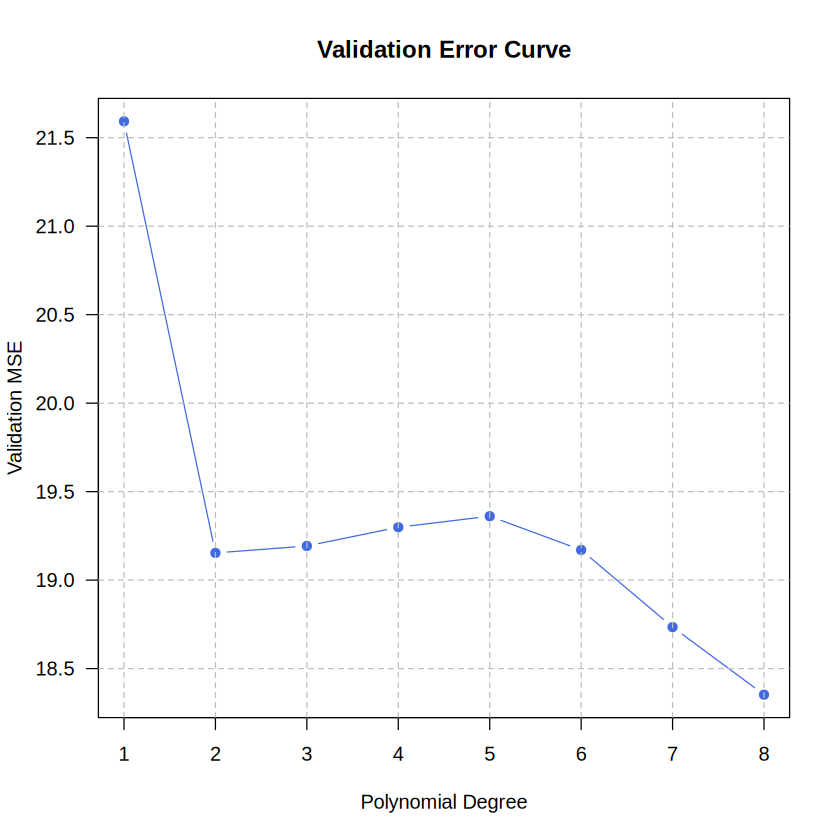

In [93]:
# length(cv.error)
degrees <- 1:8
mse_values <- c(cv.error)
plot(degrees, mse_values, type = "b", pch = 19, col = "royalblue",
     xlab = "Polynomial Degree", ylab = "Validation MSE",
     main = "Validation Error Curve", las = 1)
grid(nx = NULL, ny = NULL, lty = 2, col = "gray")

#K-Fold Cross-Validation
Performing 5 & 10 Fold crossvalidation on mpg ~ acceleration.
Basically partition the set into k equal sections.
Train the model on k-1 folds, and test its performance on the one left out.
do this until each partition has been left once, and been tested against.
last, we take the MSE for our left-out results and plot them. this measures how well the model will do on previously unseen data

_important note_

the partitions are assined randomly so changing the seed value will also change how those partitions are shuffled... which is what causes the final curves to shift with each run

#### TASK 4) Select a different feature form Auto than you did in task 3 and perform a 5 fold and 10 fold k-fold cross validation. Again be sure to use your ID as a seed.

In [94]:
#5 Fold CV
set.seed(7829)
cv.error.5 <- rep(0, 5)
for(i in 1:5) {
  glm.fit <- glm(mpg ~ poly(acceleration, i), data = Auto)
  cv.error.5[i] <- cv.glm(Auto, glm.fit, K = 5)$delta[1]
}
cv.error.5

[1] 50.34897 50.18340 50.16309 50.31169 49.46200

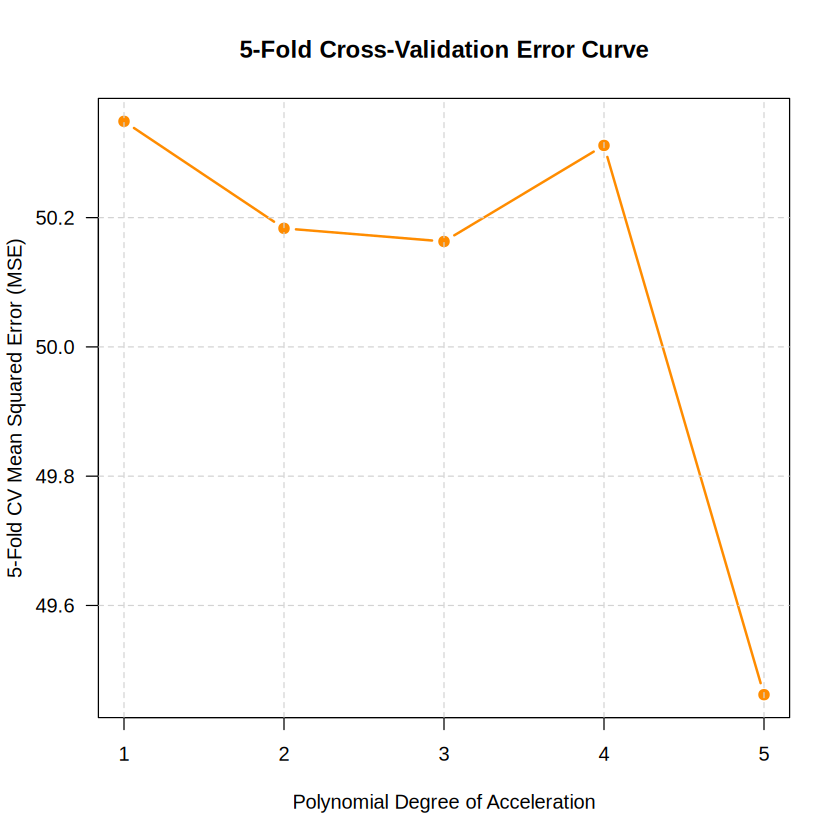

In [95]:
#Disclosure: GEMINI was used to generate the plot
# 1. Generate the base line plot ('b' plots both lines and points)
plot(1:5, cv.error.5, type = "b", pch = 19, col = "darkorange", lwd = 2,
     xlab = "Polynomial Degree of Acceleration",
     ylab = "5-Fold CV Mean Squared Error (MSE)",
     main = "5-Fold Cross-Validation Error Curve", las = 1)

# 2. Add gridlines to isolate the minimum point
grid(nx = NULL, ny = NULL, lty = 2, col = "lightgray")


In [96]:
# 10 Fold CV
set.seed(7829)
cv.error.10 <- rep(0, 10)
for(i in 1:10) {
  glm.fit <- glm(mpg ~ poly(acceleration, i), data = Auto)
  cv.error.10[i] <- cv.glm(Auto, glm.fit, K = 10)$delta[1]
}
cv.error.10

[1] 50.43148 49.67986 50.25249 49.15703 50.57700 49.52525 50.83401 51.53390
 [9] 50.50237 51.14321

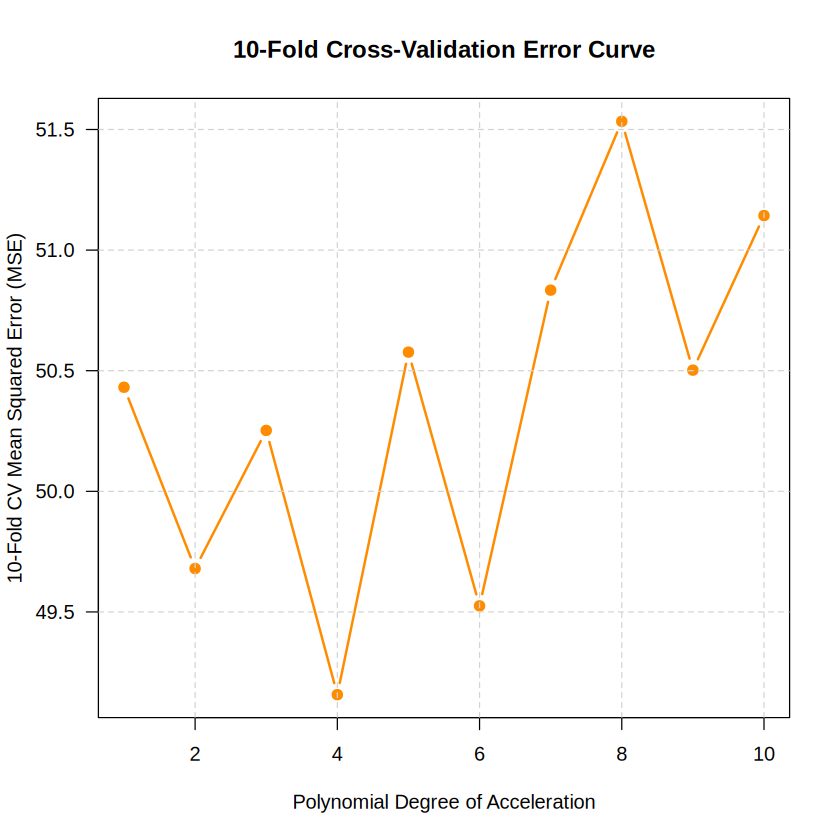

In [97]:
#Disclosure: GEMINI was used to generate the plot

# 1. Generate the base line plot ('b' plots both lines and points)
plot(1:10, cv.error.10, type = "b", pch = 19, col = "darkorange", lwd = 2,
     xlab = "Polynomial Degree of Acceleration",
     ylab = "10-Fold CV Mean Squared Error (MSE)",
     main = "10-Fold Cross-Validation Error Curve", las = 1)

# 2. Add gridlines to isolate the minimum point
grid(nx = NULL, ny = NULL, lty = 2, col = "lightgray")


#The Bootstrap / Bootstrap Analysis
This stat extrapolation tech can be used in almost all situations.
It involves just 2 steps:
- Creating a function that computes some statistic of interest
- the `boot` function - which resamples repetedly with replacement from the original sample

For this section, I will run bootstrap on ISLR2's `Portfolio` dataset to estimate a few global statistic metrics from a sample .

In [98]:
alpha.fn <- function(data, index) {
  X <- data$X[index]
  Y <- data$Y[index]
  (var(Y) - cov(X, Y)) / (var(X) + var(Y) - 2 * cov(X, Y))
}

In [99]:
alpha.fn(Portfolio, 1:100)

[1] 0.5758321

In [100]:
set.seed(7829)
alpha.fn(Portfolio, sample(100, 100, replace = T))

[1] 0.6170244

This automates bootstrap analysis - performing alpha.fn estimation 1000 times

In [101]:
boot(Portfolio, alpha.fn, R = 1000)


ORDINARY NONPARAMETRIC BOOTSTRAP


Call:
boot(data = Portfolio, statistic = alpha.fn, R = 1000)


Bootstrap Statistics :
     original        bias    std. error
t1* 0.5758321 -0.0006908914  0.09214435

In [102]:
boot.fn <- function(data, index)
  coef(lm(mpg ~ horsepower, data = data, subset = index))
boot.fn(Auto, 1:392)

(Intercept)  horsepower 
 39.9358610  -0.1578447

In [103]:
set.seed(7829)
boot.fn(Auto, sample(392, 392, replace = T))

(Intercept)  horsepower 
 39.1039364  -0.1512773

In [104]:
boot.fn(Auto, sample(392, 392, replace = T))


(Intercept)  horsepower 
 39.8586645  -0.1563317

Running the boot command to compute STDE of 1000 estimates

In [105]:
boot(Auto, boot.fn, 1000)


ORDINARY NONPARAMETRIC BOOTSTRAP


Call:
boot(data = Auto, statistic = boot.fn, R = 1000)


Bootstrap Statistics :
      original        bias    std. error
t1* 39.9358610  0.0171371570 0.861917767
t2* -0.1578447 -0.0002451524 0.007589346

In [106]:
summary(lm(mpg ~ horsepower, data = Auto))$coef

,Estimate,Std. Error,t value,Pr(>|t|)
(Intercept),39.9358610,0.717498656,55.65984,1.220362e-187
horsepower,-0.1578447,0.006445501,-24.48914,7.031989e-81


In [107]:
boot.fn <- function(data, index)
  coef(
      lm(mpg ~ horsepower + I(horsepower^2),
        data = data, subset = index)
    )
set.seed(7829)
boot(Auto, boot.fn, 1000)


ORDINARY NONPARAMETRIC BOOTSTRAP


Call:
boot(data = Auto, statistic = boot.fn, R = 1000)


Bootstrap Statistics :
        original        bias    std. error
t1* 56.900099702 -6.074540e-03 2.065412058
t2* -0.466189630 -8.689888e-05 0.033028139
t3*  0.001230536  1.151834e-06 0.000119656

In [108]:
summary(
    lm(mpg ~ horsepower + I(horsepower^2), data = Auto)
  )$coef

,Estimate,Std. Error,t value,Pr(>|t|)
(Intercept),56.900099702,1.8004268063,31.60367,1.740911e-109
horsepower,-0.466189630,0.0311246171,-14.97816,2.289429e-40
I(horsepower^2),0.001230536,0.0001220759,10.08009,2.196340e-21


#### Task 5) Compute the last bootstrap exercise (the quadratic fit for horsepower) from the lab 3 more times, using a new number of samples {250, 500, 2500}.

The goal of this task will be to compare the error estimates of the increasing number of samples. Report your observations about the error as the number of bootstrap sets increases.  Again be sure to use your ID as a seed.

In [109]:
set.seed(7829)
boot(Auto, boot.fn, 250)
set.seed(7829)
boot(Auto, boot.fn, 500)
set.seed(7829)
boot(Auto, boot.fn, 2500)


ORDINARY NONPARAMETRIC BOOTSTRAP


Call:
boot(data = Auto, statistic = boot.fn, R = 250)


Bootstrap Statistics :
        original        bias     std. error
t1* 56.900099702  7.581548e-02 2.0623811586
t2* -0.466189630 -1.080055e-03 0.0327213649
t3*  0.001230536  3.888304e-06 0.0001180775


ORDINARY NONPARAMETRIC BOOTSTRAP


Call:
boot(data = Auto, statistic = boot.fn, R = 500)


Bootstrap Statistics :
        original        bias    std. error
t1* 56.900099702  9.451283e-02 2.071980039
t2* -0.466189630 -1.417751e-03 0.033009968
t3*  0.001230536  4.995823e-06 0.000119282


ORDINARY NONPARAMETRIC BOOTSTRAP


Call:
boot(data = Auto, statistic = boot.fn, R = 2500)


Bootstrap Statistics :
        original        bias     std. error
t1* 56.900099702  1.655521e-02 2.0983756989
t2* -0.466189630 -3.461653e-04 0.0335085003
t3*  0.001230536  1.877650e-06 0.0001212045

From [R= 250, R = 500, R = 2500],
- intercept error goes from 2.0623 to 2.0719, to 2.0983
- hp error goes frm 0.0327 to 0.0330 to 0.0335
- hp^2 effor goes from 0.000118, to 0.000119 to 0.000121

It is clear from these 3 observations in isolation that std error changed most significantly when increasing our samples quantity from 250 to 500. The error for all estimates (intercept, hp, and hp^2) increase slightly across the interval. From 500 to 2500 we see similar increases across all 3 components

using the sheeps and goats analogy: smaller samples look increasingly less homogenous and therefore statistics extrapolated from them are subject to high variation due to random chance of having an overrepresented subset. increasing the sample quantity statistically homoginizes the exprapolated stats - which gives us a more reliable measure of the true global sample statistic